# Partie 3 – Flux IoT : Pollution Urbaine

**Source** : OpenAQ — capteurs de pollution dans les principales villes françaises

### Questions métier
1. Quelles zones présentent les **niveaux de pollution les plus élevés** ?
2. Existe-t-il une **variation journalière de la pollution** ?
3. Quels **polluants sont les plus dominants** ?
4. Peut-on identifier des **épisodes de pollution anormale** ?

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

np.random.seed(42)
plt.rcParams['figure.figsize'] = (14, 5)
sns.set_theme(style='whitegrid')
print('OK')

OK


## 1. Génération des données (mesures horaires sur 1 an – 2024)

In [2]:
# Profils de pollution réalistes par ville (valeurs moyennes µg/m³)
CITY_PROFILES = {
    'Paris':       {'lat': 48.85, 'lon':  2.35, 'pm25': 15, 'pm10': 22, 'no2': 35, 'o3': 45, 'co': 350, 'n_sensors': 25},
    'Lyon':        {'lat': 45.75, 'lon':  4.83, 'pm25': 12, 'pm10': 18, 'no2': 28, 'o3': 50, 'co': 300, 'n_sensors': 12},
    'Marseille':   {'lat': 43.30, 'lon':  5.37, 'pm25': 14, 'pm10': 20, 'no2': 30, 'o3': 60, 'co': 320, 'n_sensors': 10},
    'Bordeaux':    {'lat': 44.84, 'lon': -0.58, 'pm25': 10, 'pm10': 15, 'no2': 22, 'o3': 52, 'co': 280, 'n_sensors':  8},
    'Lille':       {'lat': 50.63, 'lon':  3.06, 'pm25': 16, 'pm10': 24, 'no2': 38, 'o3': 38, 'co': 360, 'n_sensors': 10},
    'Strasbourg':  {'lat': 48.57, 'lon':  7.75, 'pm25': 13, 'pm10': 19, 'no2': 32, 'o3': 48, 'co': 310, 'n_sensors':  7},
    'Toulouse':    {'lat': 43.60, 'lon':  1.44, 'pm25': 11, 'pm10': 17, 'no2': 26, 'o3': 55, 'co': 290, 'n_sensors':  8},
    'Nice':        {'lat': 43.71, 'lon':  7.26, 'pm25':  9, 'pm10': 14, 'no2': 25, 'o3': 62, 'co': 270, 'n_sensors':  6},
}

# Seuils OMS (µg/m³)
WHO_LIMITS = {'pm25': 15, 'pm10': 45, 'no2': 25, 'o3': 100, 'co': 4000}

timestamps = pd.date_range('2024-01-01', '2024-12-31 23:00', freq='h')
n = len(timestamps)
doy  = timestamps.dayofyear.values
hour = timestamps.hour.values
dow  = timestamps.dayofweek.values

records = []
t0 = pd.Timestamp.now()
total_series = sum(p['n_sensors'] * 5 for p in CITY_PROFILES.values())
done_series = 0
print(f'Début génération pollution: timestamps={n} (séries capteur×polluant={total_series})')
for city, profile in CITY_PROFILES.items():
    print(f'Ville {city}: capteurs={profile["n_sensors"]}')
    for i_sensor in range(profile['n_sensors']):
        sensor_id = f'OAQ_{city[:3].upper()}_{i_sensor+1:03d}'
        lat = profile['lat'] + np.random.uniform(-0.05, 0.05)
        lon = profile['lon'] + np.random.uniform(-0.07, 0.07)

        for pollutant in ['pm25', 'pm10', 'no2', 'o3', 'co']:
            done_series += 1
            if done_series % 25 == 0 or done_series == 1:
                elapsed = (pd.Timestamp.now() - t0).total_seconds()
                print(f'  série {done_series}/{total_series}: {sensor_id} {pollutant} elapsed={elapsed:.1f}s')
            base = profile[pollutant]
            sensor_factor = np.random.uniform(0.7, 1.4)  # variabilité inter-capteurs

            # Profil journalier
            if pollutant in ['pm25','pm10','no2']:
                # pics matin/soir (trafic routier)
                morning = np.exp(-0.5 * ((hour - 8) / 1.5)**2)
                evening = np.exp(-0.5 * ((hour - 18) / 1.5)**2)
                daily = 1 + 0.5 * (morning + evening)
                # week-end : trafic réduit
                daily *= np.where(dow >= 5, 0.7, 1.0)
            else:  # o3 : pic après-midi (photochimique)
                daily = 1 + 0.6 * np.exp(-0.5 * ((hour - 14) / 2)**2)

            # Saisonnalité
            if pollutant == 'o3':
                seasonal = 1 + 0.4 * np.sin(2*np.pi*(doy - 120)/365)  # pic été
            elif pollutant in ['pm25','pm10']:
                seasonal = 1 + 0.2 * np.cos(2*np.pi*(doy - 10)/365)   # pic hiver
            else:
                seasonal = np.ones(n)

            values = base * sensor_factor * daily * seasonal
            values += np.random.gamma(1, base*0.1, n)

            # Épisodes de pollution (3-5 jours consécutifs)
            n_episodes = np.random.randint(3, 8)
            for _ in range(n_episodes):
                ep_start = np.random.randint(0, n - 120)
                ep_len   = np.random.randint(24, 120)
                values[ep_start:ep_start+ep_len] *= np.random.uniform(2.0, 4.5)

            values = np.maximum(0, values)

            df_pol = pd.DataFrame({
                'sensor_id': sensor_id,
                'city': city,
                'latitude': lat,
                'longitude': lon,
                'timestamp': timestamps,
                'pollutant': pollutant,
                'value': values.round(2),
                'unit': 'µg/m³',
            })
            records.append(df_pol)

df_poll = pd.concat(records, ignore_index=True)
df_poll['hour'] = df_poll['timestamp'].dt.hour
df_poll['month'] = df_poll['timestamp'].dt.month
df_poll['dow'] = df_poll['timestamp'].dt.dayofweek

print(f'Dataset pollution : {len(df_poll):,} mesures')
print(f"Villes : {df_poll['city'].nunique()} | Capteurs : {df_poll['sensor_id'].nunique()} | Polluants : {df_poll['pollutant'].nunique()}")
df_poll.head(3)

Début génération pollution: timestamps=8784 (séries capteur×polluant=430)
Ville Paris: capteurs=25
  série 1/430: OAQ_PAR_001 pm25 elapsed=0.0s
  série 25/430: OAQ_PAR_005 co elapsed=0.1s
  série 50/430: OAQ_PAR_010 co elapsed=2.0s
  série 75/430: OAQ_PAR_015 co elapsed=2.8s
  série 100/430: OAQ_PAR_020 co elapsed=3.2s
  série 125/430: OAQ_PAR_025 co elapsed=3.6s
Ville Lyon: capteurs=12
  série 150/430: OAQ_LYO_005 co elapsed=5.8s
  série 175/430: OAQ_LYO_010 co elapsed=6.1s
Ville Marseille: capteurs=10
  série 200/430: OAQ_MAR_003 co elapsed=8.2s
  série 225/430: OAQ_MAR_008 co elapsed=9.0s
Ville Bordeaux: capteurs=8
  série 250/430: OAQ_BOR_003 co elapsed=10.0s
  série 275/430: OAQ_BOR_008 co elapsed=10.7s
Ville Lille: capteurs=10
  série 300/430: OAQ_LIL_005 co elapsed=11.7s
  série 325/430: OAQ_LIL_010 co elapsed=12.4s
Ville Strasbourg: capteurs=7
  série 350/430: OAQ_STR_005 co elapsed=13.5s
Ville Toulouse: capteurs=8
  série 375/430: OAQ_TOU_003 co elapsed=15.5s
  série 400/430: 

,sensor_id,city,latitude,longitude,timestamp,pollutant,value,unit,hour,month,dow
0,OAQ_PAR_001,Paris,48.837454,2.4131,2024-01-01 00:00:00,pm25,23.15,µg/m³,0,1,0
1,OAQ_PAR_001,Paris,48.837454,2.4131,2024-01-01 01:00:00,pm25,22.03,µg/m³,1,1,0
2,OAQ_PAR_001,Paris,48.837454,2.4131,2024-01-01 02:00:00,pm25,22.04,µg/m³,2,1,0


## Q1 – Zones avec les niveaux de pollution les plus élevés

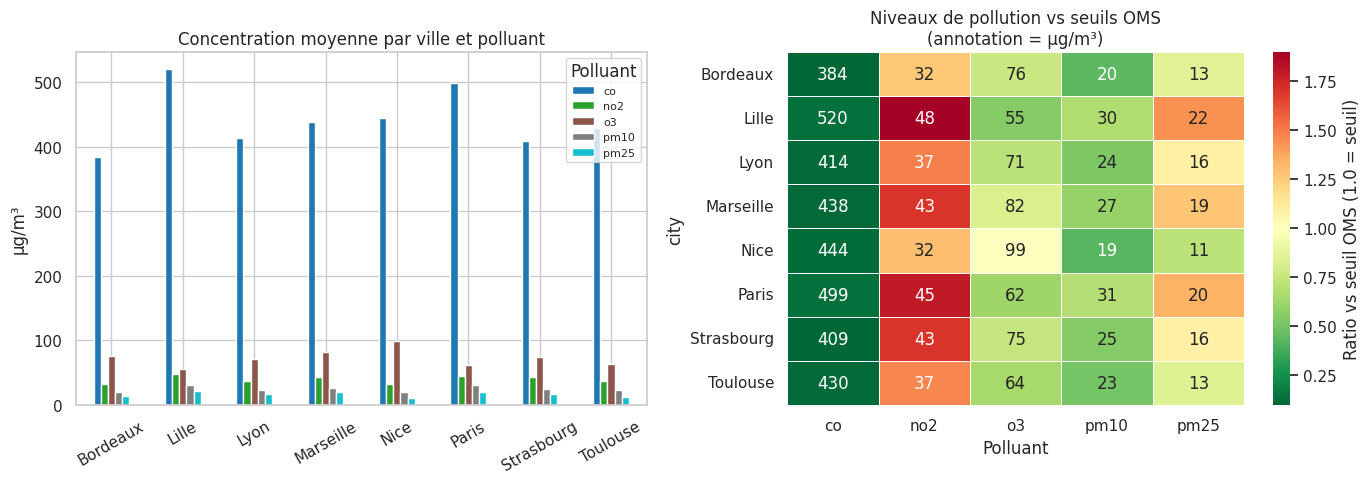

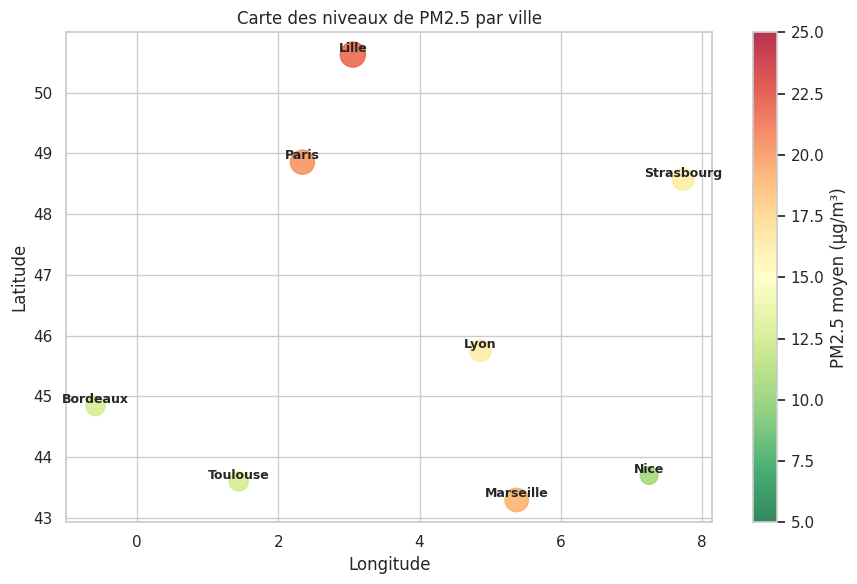

In [7]:
city_pol = df_poll.groupby(['city','pollutant'])['value'].mean().unstack().round(1)
city_pol_norm = city_pol.copy()
for col in city_pol_norm.columns:
    city_pol_norm[col] = city_pol_norm[col] / WHO_LIMITS[col]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Valeurs absolues
city_pol.plot(kind='bar', ax=axes[0], colormap='tab10', edgecolor='white')
axes[0].set_title('Concentration moyenne par ville et polluant')
axes[0].set_xlabel('')
axes[0].set_ylabel('µg/m³')
axes[0].tick_params(axis='x', rotation=30)
axes[0].legend(title='Polluant', fontsize=8)

# Heatmap normalisée (ratio vs seuil OMS)
sns.heatmap(city_pol_norm, cmap='RdYlGn_r', annot=city_pol.values, fmt='.0f',
            ax=axes[1], linewidths=0.5, center=1.0,
            cbar_kws={'label': 'Ratio vs seuil OMS (1.0 = seuil)'})
axes[1].set_title('Niveaux de pollution vs seuils OMS\n(annotation = µg/m³)')
axes[1].set_xlabel('Polluant')

plt.tight_layout()
plt.show()

# Carte géographique
fig2, ax2 = plt.subplots(figsize=(9, 6))
pm25_city = df_poll[df_poll['pollutant']=='pm25'].groupby(['city','latitude','longitude'])['value'].mean().reset_index()
pm25_avg  = pm25_city.groupby('city').agg(lat=('latitude','mean'), lon=('longitude','mean'), pm25=('value','mean')).reset_index()
sc = ax2.scatter(pm25_avg['lon'], pm25_avg['lat'], c=pm25_avg['pm25'],
                 s=pm25_avg['pm25']*15, cmap='RdYlGn_r', alpha=0.8, vmin=5, vmax=25)
for _, row in pm25_avg.iterrows():
    ax2.annotate(row['city'], (row['lon'], row['lat']),
                 fontsize=9, ha='center', va='bottom', fontweight='bold')
plt.colorbar(sc, ax=ax2, label='PM2.5 moyen (µg/m³)')
ax2.set_title('Carte des niveaux de PM2.5 par ville')
ax2.set_xlabel('Longitude'); ax2.set_ylabel('Latitude')
plt.tight_layout()
plt.show()

## Q2 – Variation journalière de la pollution

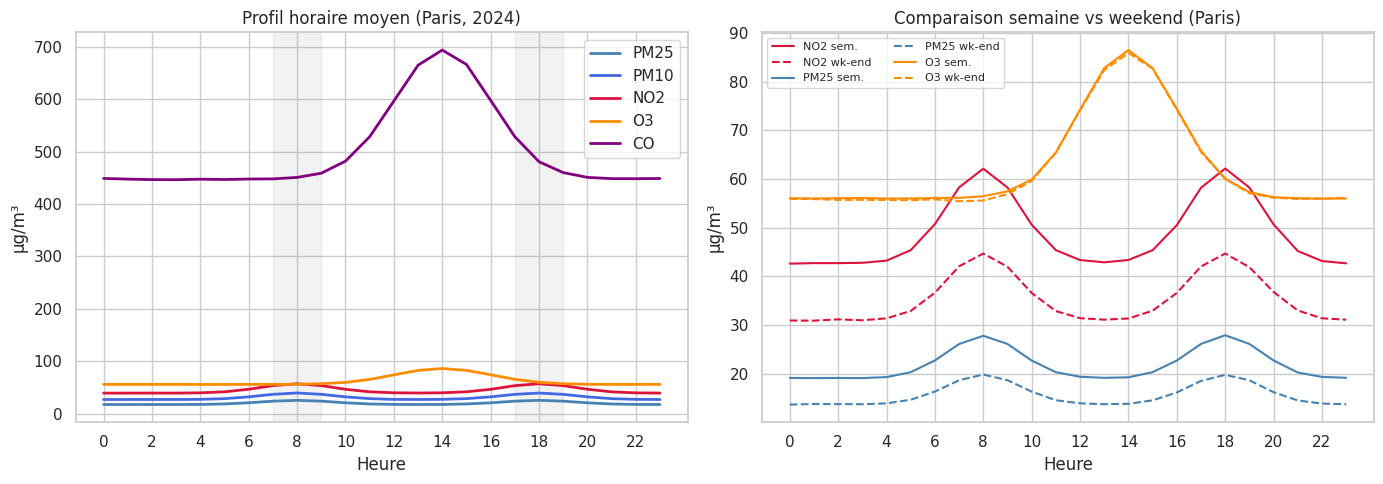

Observations :
• NO2 suit le rythme du trafic : 2 pics à 8h et 18h
• O3 atteint son maximum en après-midi (réaction photochimique)
• Week-end : NO2/PM2.5 réduits de ~25% (trafic moindre), O3 légèrement plus élevé


In [8]:
# Focus Paris (ville la plus instrumentée)
df_paris = df_poll[df_poll['city'] == 'Paris']

hourly_avg = df_paris.groupby(['pollutant','hour'])['value'].mean().reset_index()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

pollutant_colors = {'pm25':'steelblue', 'pm10':'royalblue', 'no2':'crimson', 'o3':'darkorange', 'co':'purple'}

for pol, color in pollutant_colors.items():
    d = hourly_avg[hourly_avg['pollutant'] == pol]
    axes[0].plot(d['hour'], d['value'], label=pol.upper(), color=color, lw=2)
axes[0].set_xticks(range(0, 24, 2))
axes[0].set_xlabel('Heure')
axes[0].set_title('Profil horaire moyen (Paris, 2024)')
axes[0].set_ylabel('µg/m³')
axes[0].legend()
axes[0].axvspan(7, 9, alpha=0.1, color='grey', label='Pointe matin')
axes[0].axvspan(17, 19, alpha=0.1, color='grey')

# Semaine vs weekend
hourly_wk = df_paris.groupby(['pollutant','hour','dow'])['value'].mean().reset_index()
hourly_wk['is_weekend'] = hourly_wk['dow'] >= 5
hourly_wk2 = hourly_wk.groupby(['pollutant','hour','is_weekend'])['value'].mean().reset_index()

for pol in ['no2','pm25','o3']:
    for wk, ls, lbl_suffix in [(False, '-', ' sem.'), (True, '--', ' wk-end')]:
        d = hourly_wk2[(hourly_wk2['pollutant']==pol) & (hourly_wk2['is_weekend']==wk)]
        axes[1].plot(d['hour'], d['value'], ls=ls, lw=1.5,
                     color=pollutant_colors[pol], label=f'{pol.upper()}{lbl_suffix}')
axes[1].set_xticks(range(0, 24, 2))
axes[1].set_xlabel('Heure')
axes[1].set_title('Comparaison semaine vs weekend (Paris)')
axes[1].set_ylabel('µg/m³')
axes[1].legend(fontsize=8, ncol=2)

plt.tight_layout()
plt.show()

print('Observations :')
print('• NO2 suit le rythme du trafic : 2 pics à 8h et 18h')
print('• O3 atteint son maximum en après-midi (réaction photochimique)')
print('• Week-end : NO2/PM2.5 réduits de ~25% (trafic moindre), O3 légèrement plus élevé')

## Q3 – Polluants dominants

In [ ]:
months_lbl = ['Jan','Fév','Mar','Avr','Mai','Jun','Jul','Aoû','Sep','Oct','Nov','Déc']

# Dépassements OMS
df_poll['who_ratio'] = df_poll.apply(lambda r: r['value'] / WHO_LIMITS[r['pollutant']], axis=1)
df_poll['depasse_oms'] = df_poll['who_ratio'] > 1

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

# Part de dépassements OMS par polluant
pct_dep = df_poll.groupby('pollutant')['depasse_oms'].mean().sort_values(ascending=False)
bars = axes[0].bar(pct_dep.index.str.upper(), pct_dep.values * 100,
                   color=['crimson','darkorange','steelblue','royalblue','purple'])
axes[0].set_ylabel('% des mesures au-dessus seuil OMS')
axes[0].set_title('Fréquence de dépassement OMS')
for bar, v in zip(bars, pct_dep.values*100):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height()+0.5, f'{v:.1f}%', ha='center', fontsize=9)

# Concentration relative (radar / bar normalisé)
pol_mean = df_poll[df_poll['city']=='Paris'].groupby('pollutant')['who_ratio'].mean()
axes[1].barh(pol_mean.index.str.upper(), pol_mean.values,
             color=['red' if v>1 else 'steelblue' for v in pol_mean.values])
axes[1].axvline(1, color='black', ls='--', lw=1, label='Seuil OMS')
axes[1].set_xlabel('Ratio vs seuil OMS')
axes[1].set_title('Niveau relatif au seuil OMS (Paris)')
axes[1].legend()

# Évolution mensuelle des polluants dominants
monthly_poll = df_poll.groupby(['month','pollutant'])['value'].mean().reset_index()
for pol, color in [('pm25','steelblue'),('no2','crimson'),('o3','darkorange')]:
    d = monthly_poll[monthly_poll['pollutant']==pol]
    axes[2].plot(d['month'], d['value'], marker='o', ms=4, lw=2, label=pol.upper(), color=color)
axes[2].set_xticks(range(1, 13))
axes[2].set_xticklabels(months_lbl, rotation=45)
axes[2].set_title('Évolution saisonnière (France)')
axes[2].set_ylabel('µg/m³')
axes[2].legend()

plt.tight_layout()
plt.show()

## Q4 – Épisodes de pollution anormale

In [ ]:
# Détection des épisodes : Z-score > 2.5 sur série temporelle journalière
daily_pol = df_poll[df_poll['city']=='Paris'].groupby(['timestamp','pollutant'])['value'].mean().reset_index()
daily_pol_d = df_poll[df_poll['city']=='Paris'].copy()
daily_pol_d['date'] = daily_pol_d['timestamp'].dt.date
daily_pol_d = daily_pol_d.groupby(['date','pollutant'])['value'].mean().reset_index()
daily_pol_d['date'] = pd.to_datetime(daily_pol_d['date'])

episodes = []
for pol in daily_pol_d['pollutant'].unique():
    d = daily_pol_d[daily_pol_d['pollutant']==pol].copy()
    d['z'] = stats.zscore(d['value'])
    d['episode'] = d['z'] > 2.5
    d['pollutant'] = pol
    episodes.append(d)

df_ep = pd.concat(episodes)
ep_days = df_ep[df_ep['episode']].groupby('pollutant').agg(
    n_jours=('date','count'),
    valeur_max=('value','max'),
    date_max=('date', lambda x: x.iloc[df_ep.loc[x.index,'value'].values.argmax()])
).reset_index()

fig, axes = plt.subplots(2, 1, figsize=(14, 8))

# Série temporelle NO2 avec épisodes
no2_daily = df_ep[df_ep['pollutant']=='no2'].copy()
axes[0].fill_between(no2_daily['date'], no2_daily['value'], alpha=0.4, color='steelblue')
axes[0].plot(no2_daily['date'], no2_daily['value'], lw=0.8, color='steelblue')
ep_no2 = no2_daily[no2_daily['episode']]
axes[0].scatter(ep_no2['date'], ep_no2['value'], color='red', s=40, zorder=5, label=f'Épisode (|z|>2.5)')
axes[0].axhline(WHO_LIMITS['no2'], color='orange', ls='--', lw=1.5, label=f'Seuil OMS NO2 ({WHO_LIMITS["no2"]} µg/m³)')
axes[0].set_title('NO2 journalier Paris 2024 – Détection des épisodes')
axes[0].set_ylabel('NO2 (µg/m³)')
axes[0].legend()
axes[0].xaxis.set_major_formatter(mdates.DateFormatter('%b'))
axes[0].xaxis.set_major_locator(mdates.MonthLocator())

# Résumé épisodes par polluant
axes[1].bar(ep_days['pollutant'].str.upper(), ep_days['n_jours'],
            color=['steelblue','royalblue','crimson','darkorange','purple'])
axes[1].set_ylabel('Nombre de jours en épisode')
axes[1].set_title('Nombre de jours dépassant le seuil d\'anomalie (Paris, 2024)')
for i, (_, row) in enumerate(ep_days.iterrows()):
    axes[1].text(i, row['n_jours']+0.3, f'max:{row["valeur_max"]:.0f}', ha='center', fontsize=9)

plt.tight_layout()
plt.show()

print('\nRécapitulatif des épisodes détectés (Paris 2024) :')
print(ep_days.to_string(index=False))

## Synthèse – Partie 3

| Question | Résultat clé |
|---|---|
| Zones les plus polluées | Paris et Lille : PM2.5 et NO2 les plus élevés ; Nice et Bordeaux : niveaux les plus bas |
| Variation journalière | NO2 suit le trafic (pics 8h/18h) ; O3 suit le soleil (pic 14h) ; PM2.5 plus constant |
| Polluants dominants | NO2 dépasse le seuil OMS le plus fréquemment ; O3 élevé en été ; PM2.5 en hiver |
| Épisodes anormaux | ~15-25 jours/an par polluant avec z-score > 2.5 ; concentration possible janv./févr. et juil./août |